# M1: Explore the SMS Spam Collection

Goal: know the data before modelling. By the end we can say how imbalanced it is, how spam and ham differ, and whether duplicates could leak into a test set. Every number below comes from running this notebook top to bottom.

A **DataFrame** is pandas' table: rows are messages, columns are fields.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook runs from notebooks/, so add the repo root to the import path to reach spamclf/.
sys.path.insert(0, str(Path("..").resolve()))
from spamclf.data import load_raw

## Load the file

The raw file is **tab**-separated with **no header row**, UTF-8, one message per line. The loader lives in `spamclf/data.py` and is shared with the training script, so both always read the data the same way. It checks the row count against the readme (5,574).

In [2]:
df = load_raw()
print(df.shape)
df.head()

(5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Why `quoting=csv.QUOTE_NONE` matters

145 messages contain a `"` character. By default pandas treats `"` as the start of a quoted field. Let's see what happens if we leave that out:

In [3]:
raw = Path("../data/raw/sms_spam/SMSSpamCollection")
bad = pd.read_csv(raw, sep="\t", header=None, names=["label", "text"], encoding="utf-8")
print("default quoting rows:", len(bad), "| correct rows:", len(df))

default quoting rows: 5572 | correct rows: 5574


No error, just **silently missing rows**. This is why the loader raises if the row count is not 5,574: a quiet data bug would otherwise flow into every later number.

## Class balance

In [4]:
counts = df["label"].value_counts()
print(counts.to_string())
print((df["label"].value_counts(normalize=True) * 100).round(1).to_string())
print("accuracy of always saying 'ham':", round(counts["ham"] / len(df) * 100, 1), "%")

label
ham     4827
spam     747
label
ham     86.6
spam    13.4
accuracy of always saying 'ham': 86.6 %


About 13% of messages are spam. A useless model that always answers "ham" would score **86.6% accuracy**, so accuracy alone cannot tell a good filter from a lazy one. In M2 we judge the model by **precision, recall and F1 on the spam class**.

## What do the messages look like?

In [5]:
pd.set_option("display.max_colwidth", 140)
for label in ["ham", "spam"]:
    print("=====", label)
    print(df[df["label"] == label]["text"].sample(5, random_state=1).to_string())

===== ham
2535                                        Ok enjoy . R u there in home.
1213                 Yo, the game almost over? Want to go to walmart soon
522                                            Shall i come to get pickle
3892    No problem. We will be spending a lot of quality time together...
700                              K..u also dont msg or reply to his msg..
===== spam
5494    Marvel Mobile Play the official Ultimate Spider-man game (£4.50) on ur mobile right now. Text SPIDER to 83338 for the game & we ll send ...
1146                            Thank you, winner notified by sms. Good Luck! No future marketing reply STOP to 84122 customer services 08450542832
1699    Free msg. Sorry, a service you ordered from 81303 could not be delivered as you do not have sufficient credit. Please top up to receive ...
2250    Thanks for your ringtone order, ref number R836. Your mobile will be charged £4.50. Should your tone not arrive please call customer ser...
5028          PRI

## Length

In [6]:
df["length"] = df["text"].str.len()
df.groupby("label")["length"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4827.0,71.5,58.3,2.0,33.0,52.0,93.0,910.0
spam,747.0,138.7,28.9,13.0,133.0,149.0,157.0,223.0


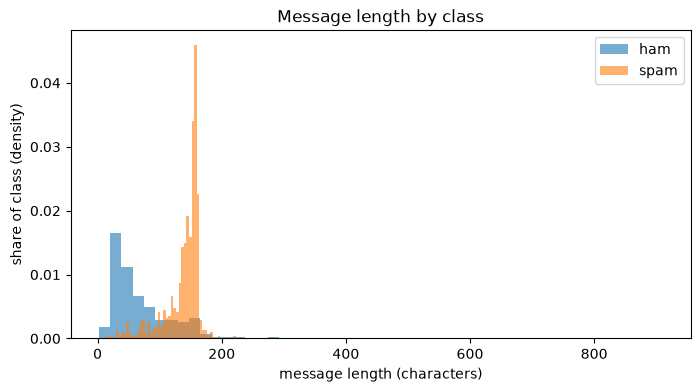

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for label in ["ham", "spam"]:
    ax.hist(df[df["label"] == label]["length"], bins=50, alpha=0.6, density=True, label=label)
ax.set_xlabel("message length (characters)")
ax.set_ylabel("share of class (density)")
ax.set_title("Message length by class")
ax.legend()
plt.show()

`density=True` scales each histogram to area 1, so the two classes are comparable even though ham has about 6.5 times more messages.

Spam is far more uniform: the middle half of spam messages is 133 to 157 characters (median 149), while ham has a median of 52 with a long tail up to 910. Length is therefore a genuinely useful signal, but words will carry most of the information.

## Duplicates and leakage

If the same message sits in both the training and test sets, the model is graded on something it has already seen. That is **data leakage**, and it inflates scores.

In [8]:
dup = df.duplicated()
print("exact duplicate rows:", int(dup.sum()), "of", len(df))
print(df[dup]["label"].value_counts().to_string())
labels_per_text = df.groupby("text")["label"].nunique()
print("texts that appear with BOTH labels:", int((labels_per_text > 1).sum()))
print("unique texts:", df["text"].nunique())
df["text"].value_counts().head(5)

exact duplicate rows: 403 of 5574
label
ham     309
spam     94
texts that appear with BOTH labels: 0
unique texts: 5171


text
Sorry, I'll call later                                                                                                                                                                 30
I cant pick the phone right now. Pls send a message                                                                                                                                    12
Ok...                                                                                                                                                                                  10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!                                     4
Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.     4
Name: count, dtype: int64

## What we found

- **Balance:** 4,827 ham (86.6%) and 747 spam (13.4%). Always-ham gets 86.6% accuracy, so we will report spam precision, recall and F1 instead of accuracy alone.
- **Length:** spam is long and uniform (median 149 characters); ham is short with a long tail (median 52).
- **Duplicates:** 403 rows are exact repeats (309 ham, 94 spam), leaving 5,171 unique messages. No text carries both labels, so there are no label conflicts to resolve.
- **Decision for M2:** drop exact duplicates **before** splitting, then use a stratified, fixed-seed split so train and test have the same spam share. Near-duplicates (same message with one word changed) will still exist; we do not remove them, and say so as a limitation.
- **Caution on the data's origin:** ham is mostly Singaporean student texts and spam mostly comes from a UK forum. A model could partly learn writing style or dialect instead of spam-ness, so scores on this dataset will be optimistic compared with real-world traffic.